# Lab 2: From Raw Data to ML-Ready Data
## Data Cleaning & Exploratory Data Analysis — Telco Customer Churn

**Name:** Muhammad Taraz

**Roll Number:** 023-24-0259

**GitHub Repository:** https://github.com/Muhammad-taraz/Machine-Learning-Journey

**Duration:** 3 Hours (independent, hands-on)

> This notebook is a **template**, not a tutorial. You already know Python, NumPy, Pandas, and Matplotlib from previous labs. Each section below states the objective and the questions you must answer — **you decide** which functions/plots are appropriate. Do not just run code without interpreting it: every visualization needs a written observation, and every cleaning decision needs a written justification.
>
> Fill in the empty code cells and the *Answer:* / *Observation:* placeholders directly in this notebook. Do not delete the Markdown headings — they are used for grading.

---

## Setup

Import the libraries you'll need and load the dataset. Use the Telco Customer Churn CSV provided for this lab.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Telco-Customer-Churn.csv")

print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

---

## Part 1 — The Business Problem

A telecommunications company is losing customers to competitors — this is called **customer churn**. The company wants to understand which customers are likely to leave, so it can intervene early. Before any model can be built, the raw data must be understood, audited for quality issues, and explored.

**Tasks**
1. In 2–3 sentences, state the business problem in your own words, and propose what the target variable likely is.
2. List 5 columns you expect to be useful predictors of churn, and 2 columns you expect to be useless as predictors — justify each choice in one line.
3. Write down 2 questions you personally want this data to answer about customers who churn.

**Answer 1:**
The company wants to understand that which customer would likely to leave its services so that it can take action early. Each row represents one customer and the likely target variable is Churn because it shows whether the customer left the company or not.

**Answer 2:**
1. Contract: Different contract types may have different churn rates.
2. tenure: Customers who stay longer may be less likely to churn.
3. MonthlyCharges: Higher monthly charges may be related to higher churn.
4. InternetService: Different internet services may have different churn behavior.
5. PaymentMethod: Payment method may show differences in customer churn.

Useless predictors:

1. customerID: It is only a unique identifier and does not describe customer behavior.
2. gender: It has only two categories and is not expected to strongly explain churn in this dataset.

**Answer 3:**
1. Do customers with month-to-month contracts churn more than customers with longer contracts?
2. Are customers with higher monthly charges more likely to churn?

---

## Part 2 — Exploring the Dataset Structure

Before cleaning or analyzing anything, get an accurate picture of the dataset's shape and contents. Running a command is not the same as understanding its output — you must interpret what you see.

*Concepts/functions you may find useful:* `df.shape`, `df.columns`, `df.dtypes`, `df.info()`, `df.head()`, `df.sample(n)`, `df[col].unique()`, `df[col].nunique()`, `df.describe(include='all')`

**Tasks**
4. How many customers and how many features are in this dataset? List the numerical features and the categorical features separately.
5. Identify any column(s) that are simply identifiers rather than predictive features, and any column(s) whose data type looks wrong for what it represents.
6. Pick 3 categorical columns and report their unique values — do any contain unexpected or inconsistent categories?

In [4]:
# Task 4 — dataset shape, column names, data types
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nNumerical columns:")
print(df.select_dtypes(include="number").columns.tolist())

print("\nCategorical columns:")
print(df.select_dtypes(include="object").columns.tolist())

Shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Numerical columns:
['SeniorCitiz

/tmp/ipykernel_8380/1517489533.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include="object").columns.tolist())


In [5]:
# Task 5 — identify identifier columns / wrong data types
print("Identifier column:")
print("customerID")

print("\nColumn with wrong data type:")
print("TotalCharges")
print("Current type:", df["TotalCharges"].dtype)

Identifier column:
customerID

Column with wrong data type:
TotalCharges
Current type: str


In [6]:
# Task 6 — unique values in 3 categorical columns
print("gender:")
print(df["gender"].unique())

print("\nContract:")
print(df["Contract"].unique())

print("\nInternetService:")
print(df["InternetService"].unique())

gender:
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

Contract:
<StringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str

InternetService:
<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str


**Observations (Part 2):**
The dataset contains 7043 customers and 21 columns. The numerical columns are SeniorCitizen, tenure, and MonthlyCharges while TotalCharges is also numerical in meaning but is currently stored as text. The customerID column is an identifier rather than a useful predictive feature. The selected categorical columns contain consistent categories without obvious spelling or formatting problems.

---

## Part 3 — Investigating Data Quality

A dataset can look clean at a glance and still hide serious problems. You must actively search for missing values, duplicates, and suspicious values rather than assume there are none.

*Concepts/functions you may find useful:* `df.isnull().sum()`, `df.isnull().mean()*100`, `df.duplicated().sum()`, `df['id_col'].duplicated().sum()`, `df[col].value_counts()`

**Tasks**
7. Report missing values as both a count and a percentage per column. Which missing-value problems do you think require action, and which don't? Justify your reasoning.
8. Check for duplicate rows and duplicate customer IDs separately — are they the same issue or different issues?
9. Find at least one column with a suspicious, invalid, or inconsistently formatted value, and describe how you found it.

In [7]:
# Task 7 — missing values: count and percentage per column
missing_count = df.isnull().sum()
missing_percent = (df.isnull().mean() * 100).round(3)

missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percent
})

print(missing_table)

                  Missing Count  Missing Percentage
customerID                    0                 0.0
gender                        0                 0.0
SeniorCitizen                 0                 0.0
Partner                       0                 0.0
Dependents                    0                 0.0
tenure                        0                 0.0
PhoneService                  0                 0.0
MultipleLines                 0                 0.0
InternetService               0                 0.0
OnlineSecurity                0                 0.0
OnlineBackup                  0                 0.0
DeviceProtection              0                 0.0
TechSupport                   0                 0.0
StreamingTV                   0                 0.0
StreamingMovies               0                 0.0
Contract                      0                 0.0
PaperlessBilling              0                 0.0
PaymentMethod                 0                 0.0
MonthlyCharg

In [8]:
# Task 8 — duplicate rows vs duplicate IDs
duplicate_rows = df.duplicated().sum()
duplicate_ids = df["customerID"].duplicated().sum()

print("Duplicate rows:", duplicate_rows)
print("Duplicate customer IDs:", duplicate_ids)

Duplicate rows: 0
Duplicate customer IDs: 0


In [9]:
# Task 9 — investigate a suspicious / invalid value
blank_total_charges = df["TotalCharges"].astype(str).str.strip() == ""

print("Blank TotalCharges values:", blank_total_charges.sum())

print("\nRows with blank TotalCharges:")
print(df.loc[blank_total_charges, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

Blank TotalCharges values: 11

Rows with blank TotalCharges:
      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No
6754  2775-SEFEE       0           61.90                 No


**Answer 7 (which missing-value problems need action, and why):**
The normal isnull() check shows no missing values but a separate check found 11 blank values in TotalCharges. These values require action because TotalCharges is a numerical feature and blank text cannot be used correctly for numerical analysis. The other columns do not show missing values.

**Answer 8 (duplicate rows vs duplicate IDs — same issue or different?):**
Duplicate rows and duplicate customer IDs are different checks. A duplicate row means the complete record is repeated, while a duplicate ID means the same customer ID appears more than once. In this dataset both are zero so no duplicate records need to be removed.

**Answer 9 (suspicious value found and how):**
The suspicious values are 11 blank entries in TotalCharges. They were found by checking for empty strings and all 11 customers have tenure equal to 0. This suggests that the blank values represent customers who have not accumulated any total charges yet.

---

## Part 4 — Data Cleaning Decisions

Cleaning is a series of justified decisions, not a fixed recipe. For every issue you fix, you must be able to explain why you chose that method over an alternative.

*Concepts/functions you may find useful:* `pd.to_numeric(s, errors='coerce')`, `df.fillna(value)`, `df.dropna()`, `df.drop_duplicates()`, `df[col].str.strip()`, `df.astype(dtype)`

**Tasks**
10. For every data-quality issue you found in Part 3, record: Problem → Decision → Method Used → Reason.
11. Apply your cleaning decisions to produce an intermediate cleaned dataframe, and confirm (with code output) that each issue is actually resolved.

**Task 10 — Cleaning Decision Log**

| Problem                        | Decision                  | Method Used          | Reason                                                                   |
| ------------------------------ | ------------------------- | -------------------- | ------------------------------------------------------------------------ |
| TotalCharges stored as text  | Convert to numeric        | pd.to_numeric()    | TotalCharges represents an amount of money and should be numerical       |
| 11 blank TotalCharges values | Replace with 0            | fillna(0)          | All 11 rows have tenure 0 so no accumulated total charge is reasonable  |
| customerID is an identifier  | Remove from final dataset | drop()             | It uniquely identifies customers but does not describe customer behavior |
| Duplicate rows                 | No removal needed         | duplicated() check | There are 0 duplicate rows                                               |
| Duplicate customer IDs         | No removal needed         | duplicated() check | There are 0 duplicate customer IDs                                       |


In [10]:
# Task 11 — apply your cleaning decisions here
clean_df = df.copy()

clean_df["TotalCharges"] = pd.to_numeric(
    clean_df["TotalCharges"],
    errors="coerce"
)

clean_df["TotalCharges"] = clean_df["TotalCharges"].fillna(0)

clean_df = clean_df.drop(columns=["customerID"])

print(clean_df.head())

   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1              Yes          No  

In [11]:
# Task 11 (continued) — confirm each issue is resolved (e.g. re-check isnull().sum(), duplicated().sum(), dtypes)
print("Missing values:")
print(clean_df.isnull().sum())

print("\nData types:")
print(clean_df.dtypes)

print("\nOriginal duplicate rows:", df.duplicated().sum())
print("Original duplicate customer IDs:", df["customerID"].duplicated().sum())

Missing values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Data types:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges  

---

## Part 5 — Univariate EDA

Look at individual variables in isolation before looking at relationships. Every chart must be followed by a written interpretation — a graph with no explanation earns no credit.

*Concepts/functions you may find useful:* `df[col].plot(kind='hist')` / `plt.hist()`, `df.boxplot(column=col)`, `df[col].value_counts().plot(kind='bar')`

**Tasks**
12. Visualize the distribution of at least 2 numerical features and 2 categorical features. For each chart, write 1–2 sentences on what you learned.
13. Do any numerical features show outliers or a skewed distribution? What might explain this?

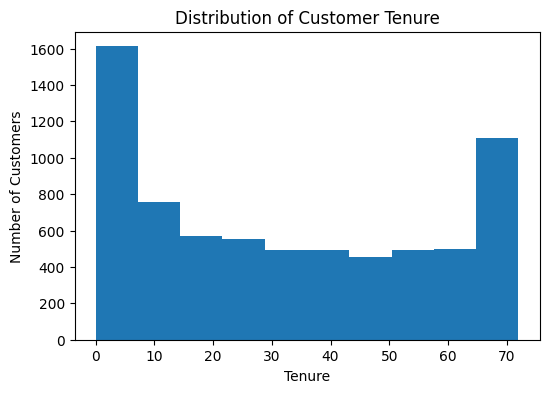

In [12]:
# Task 12 — numerical feature 1: distribution plot
plt.figure(figsize=(6, 4))

plt.hist(clean_df["tenure"], bins=10)

plt.xlabel("Tenure")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Tenure")

plt.show()

**Observation:** Most customers are spread across different tenure levels with many customers having relatively low to medium tenure. The distribution also shows that the dataset contains both new and long-term customers.

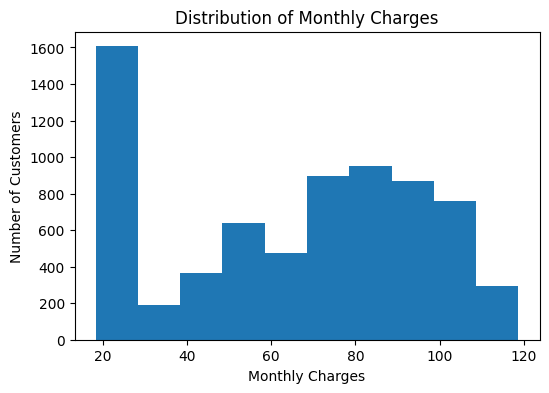

In [13]:
# Task 12 — numerical feature 2: distribution plot
plt.figure(figsize=(6, 4))

plt.hist(clean_df["MonthlyCharges"], bins=10)

plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.title("Distribution of Monthly Charges")

plt.show()

**Observation:** Monthly charges are spread across a wide range of values. Most customers have charges around the middle range while fewer customers have very low or very high monthly charges.

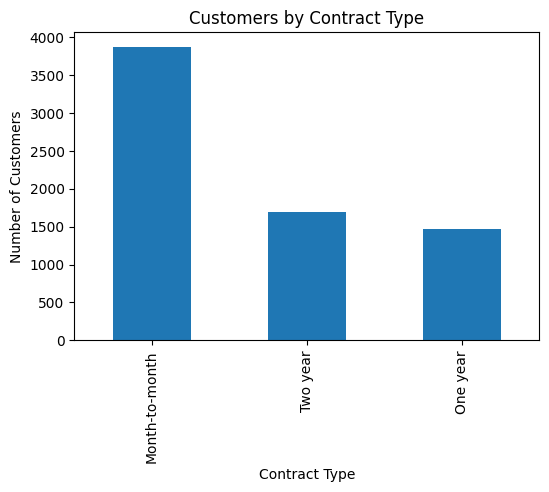

In [14]:
# Task 12 — categorical feature 1: distribution plot
plt.figure(figsize=(6, 4))

clean_df["Contract"].value_counts().plot(kind="bar")

plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.title("Customers by Contract Type")

plt.show()

**Observation:** Month-to-month contracts are the most common in the dataset. One-year and two-year contracts have fewer customers with two-year contracts being the least common.

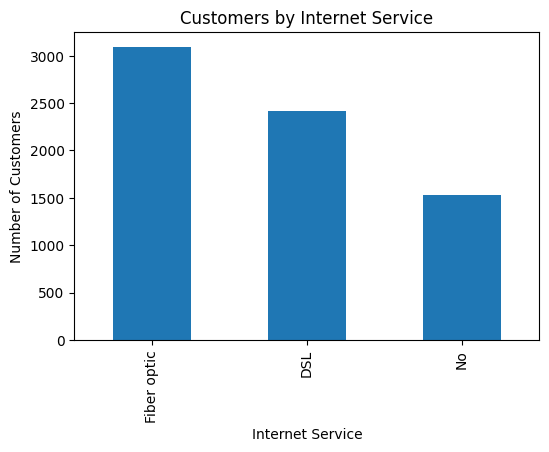

In [15]:
# Task 12 — categorical feature 2: distribution plot
plt.figure(figsize=(6, 4))

clean_df["InternetService"].value_counts().plot(kind="bar")

plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.title("Customers by Internet Service")

plt.show()

**Observation:** Fiber optic is the most common internet service followed by DSL. A smaller group of customers does not have internet service.

**Answer 13 (outliers / skew and possible explanation):**
_(your answer here)_

---

## Part 6 — Target Variable Analysis

The `Churn` column is what you will eventually predict. Before Lab 3, you need to understand its distribution — this has direct consequences for how a model should later be trained and evaluated.

*Concepts/functions you may find useful:* `df['Churn'].value_counts()`, `df['Churn'].value_counts(normalize=True)`

**Tasks**
14. Report the number and percentage of churned vs. non-churned customers. Is the target balanced or imbalanced?
15. In 2–3 sentences, explain why class imbalance might matter when a classification model is trained later — do not describe how to fix it, just why it matters.

In [16]:
# Task 14 — churn counts and percentages
churn_count = clean_df["Churn"].value_counts()
churn_percent = clean_df["Churn"].value_counts(normalize=True) * 100

print("Churn count:")
print(churn_count)

print("\nChurn percentage:")
print(churn_percent.round(2))

Churn count:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


**Answer 14 (balanced or imbalanced?):**
The target variable is imbalanced. About 73.46% of customers did not churn while 26.54% of customers churned. The two classes are therefore not equally represented.

**Answer 15 (why imbalance might matter later):**
Class imbalance matters because a model may perform well on the larger class while performing poorly on the smaller churn class. This is important because the company is specifically interested in identifying customers who are likely to churn.

---

## Part 7 — Bivariate Analysis: Features vs. Churn

Now connect individual features to the target. You choose the appropriate visualization or summary for each feature type — a categorical feature is not explored the same way as a numerical one.

*Concepts/functions you may find useful:* `pd.crosstab(df[col], df['Churn'], normalize='index')`, `df.groupby(col)['Churn']...`, `sns.boxplot(x='Churn', y=col, data=df)`

**Tasks**
16. Investigate at least 2 categorical features (e.g. Contract, InternetService, PaymentMethod) against Churn. For each, record: Observation / Evidence / Possible Explanation.
17. Investigate at least 2 numerical features (e.g. tenure, MonthlyCharges) against Churn using the same Observation / Evidence / Possible Explanation format.

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


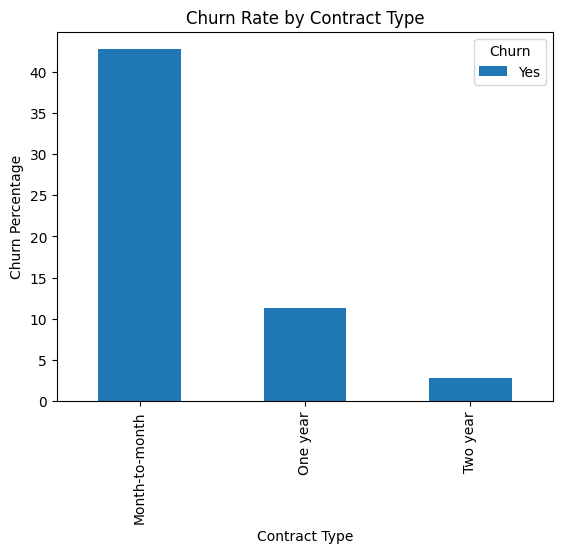

In [17]:
# Task 16 — categorical feature 1 vs Churn
contract_churn = pd.crosstab(
    clean_df["Contract"],
    clean_df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

contract_churn[["Yes"]].plot(kind="bar")

plt.xlabel("Contract Type")
plt.ylabel("Churn Percentage")
plt.title("Churn Rate by Contract Type")

plt.show()

**Observation:** Month-to-month customers have a much higher churn rate than customers with one-year or two-year contracts.

**Evidence:** The churn rate is about 42.71% for month-to-month customers 11.27% for one-year customers and 2.83% for two-year customers.

**Possible Explanation:** Customers with short-term contracts may have more flexibility to leave the company while longer contracts may encourage customers to stay for a longer period.

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


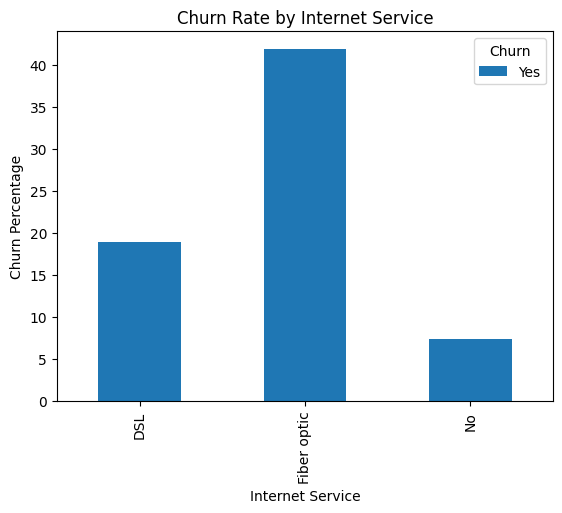

In [18]:
# Task 16 — categorical feature 2 vs Churn
internet_churn = pd.crosstab(
    clean_df["InternetService"],
    clean_df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

internet_churn[["Yes"]].plot(kind="bar")

plt.xlabel("Internet Service")
plt.ylabel("Churn Percentage")
plt.title("Churn Rate by Internet Service")

plt.show()

**Observation:** Fiber optic customers have the highest churn rate among the three internet service groups.

**Evidence:** The churn rate is about 41.89% for Fiber optic 18.96% for DSL and 7.40% for customers with no internet service.

**Possible Explanation:** Fiber optic customers may have higher charges or different service expectations which could be related to their higher churn rate.

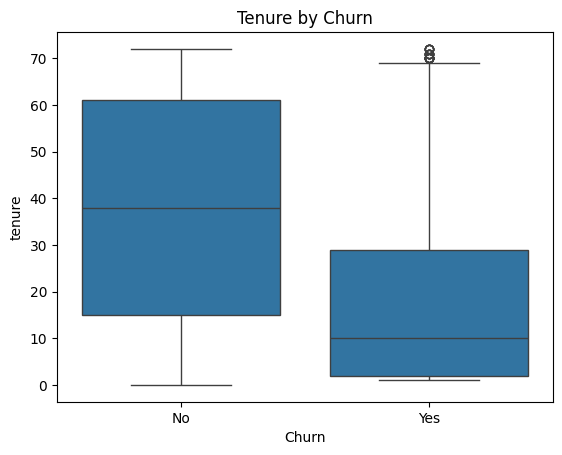

In [19]:
# Task 17 — numerical feature 1 vs Churn
sns.boxplot(x="Churn", y="tenure", data=clean_df)

plt.title("Tenure by Churn")
plt.show()

**Observation:** Customers who churn generally have lower tenure than customers who stay.

**Evidence:** The average tenure of customers who churn is about 17.98 months while customers who do not churn have an average tenure of about 37.57 months.

**Possible Explanation:** Customers with shorter relationships with the company may be less attached to the service and may leave more easily.

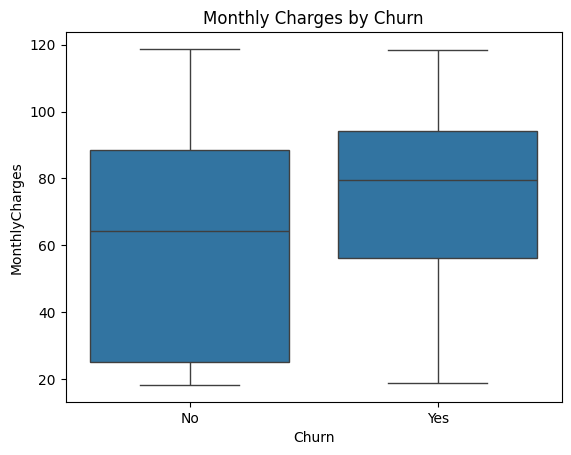

In [20]:
# Task 17 — numerical feature 2 vs Churn
sns.boxplot(x="Churn", y="MonthlyCharges", data=clean_df)

plt.title("Monthly Charges by Churn")
plt.show()

**Observation:** Customers who churn generally have higher monthly charges than customers who stay.

**Evidence:** The average monthly charge for churned customers is about 74.44 compared with about 61.27 for customers who did not churn.

**Possible Explanation:** Higher monthly charges may make customers more sensitive to price or may be associated with service packages that have higher churn.

---

## Part 8 — Correlation & Feature Relationships

Numerical features can be related to each other, not just to the target. Strongly correlated features can cause redundancy problems later, so it's worth knowing about them now.

*Concepts/functions you may find useful:* `df.corr(numeric_only=True)`, `sns.heatmap(corr_matrix, annot=True)`

**Tasks**
18. Compute and visualize the correlation matrix of the numerical features. Which pairs appear most correlated?
19. Does correlation imply causation here? Could any highly correlated features cause problems for a future model? Answer in 2–3 sentences.

                SeniorCitizen  tenure  MonthlyCharges  TotalCharges
SeniorCitizen            1.00    0.02            0.22          0.10
tenure                   0.02    1.00            0.25          0.83
MonthlyCharges           0.22    0.25            1.00          0.65
TotalCharges             0.10    0.83            0.65          1.00


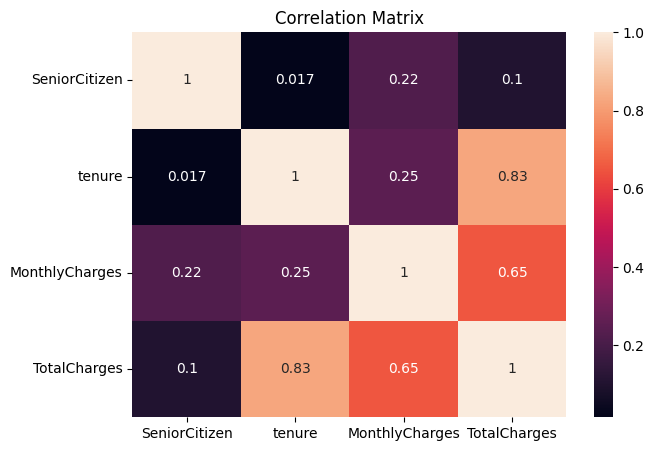

In [21]:
# Task 18 — correlation matrix and heatmap
corr_matrix = clean_df.corr(numeric_only=True)

print(corr_matrix.round(2))

plt.figure(figsize=(7, 5))

sns.heatmap(corr_matrix, annot=True)

plt.title("Correlation Matrix")

plt.show()

**Answer 18 (most correlated pairs):**
The strongest relationship is between tenure and TotalCharges with a correlation of about 0.83. MonthlyCharges and TotalCharges also have a fairly strong positive correlation of about 0.65.

**Answer 19 (correlation vs. causation; potential problems):**
The strongest relationship is between tenure and TotalCharges with a correlation of about 0.83. MonthlyCharges and TotalCharges also have a fairly strong positive correlation of about 0.65.

---

## Part 9 — Data Leakage Awareness

In Lab 3 you will train a classifier. Before that, you must check whether any column contains information that would not realistically be available at the moment of prediction — using such a column would make a model look artificially accurate.

**Tasks**
20. Inspect the columns for anything that looks like it could only be known after a customer has already churned, or that is purely an identifier. List any suspects and explain your reasoning.
21. In 2–3 sentences, explain what would go wrong if such a column were left in the model's input features.

**Answer 20 (suspect columns and reasoning):**
The main suspect is customerID because it is only an identifier and should not be used as a predictive feature. Churn itself is also not an input feature because it is the target we want to predict. I did not find another obvious column that represents information only known after the customer has already churned.

**Answer 21 (what would go wrong):**
If customerID were included as a model feature the model could learn meaningless customer-specific patterns instead of useful relationships in the data. Including information that is only known after churn would also cause data leakage and make the model appear more accurate than it would be in a real prediction situation.

---

## Part 10 — ML-Readiness Checklist

Summarize every column's fate in a single table. This is the bridge between EDA and modeling — Lab 3 will use this table directly.

**Task**
22. Complete the ML-readiness table for **every** column in the dataset.

| Column           | Type        | Role       | Action                          | Reason                                                               |
| ---------------- | ----------- | ---------- | ------------------------------- | -------------------------------------------------------------------- |
| customerID       | Identifier  | Identifier | Remove                          | Unique ID, not useful customer behavior information                  |
| gender           | Categorical | Feature    | Keep                            | Customer demographic information                                     |
| SeniorCitizen    | Numerical   | Feature    | Keep                            | Customer characteristic                                              |
| Partner          | Categorical | Feature    | Keep                            | Customer demographic information                                     |
| Dependents       | Categorical | Feature    | Keep                            | Customer demographic information                                     |
| tenure           | Numerical   | Feature    | Keep                            | Represents customer relationship length                              |
| PhoneService     | Categorical | Feature    | Keep                            | Represents subscribed service                                        |
| MultipleLines    | Categorical | Feature    | Keep                            | Represents phone service details                                     |
| InternetService  | Categorical | Feature    | Keep                            | Represents internet service type                                     |
| OnlineSecurity   | Categorical | Feature    | Keep                            | Represents subscribed service                                        |
| OnlineBackup     | Categorical | Feature    | Keep                            | Represents subscribed service                                        |
| DeviceProtection | Categorical | Feature    | Keep                            | Represents subscribed service                                        |
| TechSupport      | Categorical | Feature    | Keep                            | Represents subscribed service                                        |
| StreamingTV      | Categorical | Feature    | Keep                            | Represents subscribed service                                        |
| StreamingMovies  | Categorical | Feature    | Keep                            | Represents subscribed service                                        |
| Contract         | Categorical | Feature    | Keep                            | Contract type is related to churn behavior                           |
| PaperlessBilling | Categorical | Feature    | Keep                            | Billing preference                                                   |
| PaymentMethod    | Categorical | Feature    | Keep                            | Payment method may relate to churn                                   |
| MonthlyCharges   | Numerical   | Feature    | Keep                            | Monthly billing amount                                               |
| TotalCharges     | Numerical   | Feature    | Convert to numeric, fill blanks | Amount is numerical and blank values occur for zero-tenure customers |
| Churn            | Categorical | Target     | Keep                            | This is the outcome to predict                                       |


---

## Part 11 — Building the Clean Dataset

Bring together every cleaning decision into one final dataframe, `clean_df`, that Lab 3 can load directly.

> Do **not** split into train/test, encode categorical variables, or train any model — that happens in Lab 3.

**Tasks**
23. Produce `clean_df` with correct data types, missing values handled, duplicates handled, and irrelevant identifier columns removed where justified. Save it (e.g. `clean_churn.csv`) alongside your notebook.
24. Print `df.info()` (or equivalent) for `clean_df` as final proof that every issue identified earlier has been resolved.

In [22]:
# Task 23 — assemble clean_df from your cleaning decisions
clean_df = df.copy()

clean_df["TotalCharges"] = pd.to_numeric(
    clean_df["TotalCharges"],
    errors="coerce"
)

clean_df["TotalCharges"] = clean_df["TotalCharges"].fillna(0)

clean_df = clean_df.drop(columns=["customerID"])

clean_df.to_csv("clean_churn.csv", index=False)

print(clean_df.head())
print("\nShape:", clean_df.shape)

   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1              Yes          No  

In [23]:
# Task 24 — final proof: info() / isnull().sum() / duplicated().sum() on clean_df
print("DataFrame information:")
clean_df.info()

print("\nTotal missing values:")
print(clean_df.isnull().sum().sum())

print("\nOriginal duplicate rows:")
print(df.duplicated().sum())

print("\nOriginal duplicate customer IDs:")
print(df["customerID"].duplicated().sum())

DataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-nul

---

## Part 12 — Key Findings & Final Reflection

Step back from the code and summarize what you actually learned about this dataset and this problem.

**Task 25 — Five Important Findings**

Repeat this block for each of your five findings.

**Finding 1**

Observation: The target variable is imbalanced with more customers staying than leaving.

Evidence: 5174 customers did not churn while 1869 customers churned. This represents 73.46% non-churn and 26.54% churn.

Interpretation: Churn is the smaller class so it will need careful attention when the classification model is trained in the next lab.

**Finding 2**

Observation: Contract type has a strong relationship with churn.

Evidence: The churn rate is about 42.71% for month-to-month customers 11.27% for one-year customers and 2.83% for two-year customers.

Interpretation: Customers with longer contracts appear much more likely to stay with the company.

**Finding 3**

Observation: Customers who churn generally have shorter tenure.

Evidence: The average tenure is about 17.98 months for churned customers compared with 37.57 months for customers who stayed.

Interpretation: Newer customers appear more likely to leave than long-term customers.

**Finding 4**

Observation: Fiber optic customers have a higher churn rate than the other internet service groups.

Evidence: The churn rate is about 41.89% for Fiber optic compared with 18.96% for DSL and 7.40% for customers without internet service.

Interpretation: Internet service type appears to be an important feature for understanding customer churn.

**Finding 5**

Observation: TotalCharges has a strong relationship with tenure and contains a small number of blank values.

Evidence: Tenure and TotalCharges have a correlation of about 0.83. There are 11 blank TotalCharges values and all of these customers have tenure equal to 0.

Interpretation: TotalCharges is strongly connected to how long a customer has stayed and the blank values can reasonably be treated as zero accumulated charges for zero-tenure customers.
---

**Task 26 — Final Reflection Questions**

1. What was the most important data-quality issue you found?

The most important data-quality issue was the 11 blank values in TotalCharges. They were not detected by the normal null check because they were stored as blank text values so they had to be identified separately and converted to numeric values.

2. What was the most interesting pattern you discovered?

The most important data-quality issue was the 11 blank values in TotalCharges. They were not detected by the normal null check because they were stored as blank text values so they had to be identified separately and converted to numeric values.

3. Which feature seems most useful for predicting churn?

Contract seems to be one of the most useful features for predicting churn because the churn rate changes greatly between contract types. Tenure also appears very useful because churned customers have much lower average tenure.

4. Which feature should probably not be used and why?

customerID should not be used because it is only an identifier. It does not represent customer behavior and could cause the model to learn meaningless customer-specific patterns.

5. What preprocessing will be required before ML modeling (conceptually — do not implement it)?

Before ML modeling categorical features will need to be converted into numerical form numerical features may need suitable scaling depending on the model and the target variable will need to be prepared for classification. These steps should be done in the next lab not in this lab.

6. What would you do next if you had another 3 hours?

With another three hours I would investigate more customer groups and compare their churn rates. I would also examine possible feature relationships in more detail and prepare the dataset carefully for the classification model in Lab 3.

---

## Bonus Tasks (Optional)

- Create one additional meaningful visualization not required above.
- Investigate a surprising customer subgroup you didn't expect to find.
- Calculate churn rate across a combination of 2+ customer segments at once.
- Identify one possible feature-engineering opportunity for Lab 3.
- Identify one possible source of bias in this dataset.

In [24]:
# Bonus — optional exploration


---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Completed all 26 tasks above, with written interpretation for every chart and decision
- [ ] A working `clean_df`, saved as `clean_churn.csv`
- [ ] A completed ML-readiness table (Part 10) covering every column
- [ ] Five Key Findings written (Part 12)
- [ ] Answered all six Final Reflection questions
- [ ] Committed and pushed this notebook + `clean_churn.csv` to your GitHub repository
- [ ] Added your GitHub repository link at the top of this notebook